# Phase 2 Option A — Heart Disease Baseline
**P.V.H.S. Vitharama · KIC-BSCCSAI-251P-008**


This implements Logistic Regression as an Option A baseline. Reported LVQ values are literature comparisons on a different cohort.


## 1 Environment setup
Install the model-library version used in the verified run.

In [1]:
import sys, subprocess, importlib.metadata as metadata
requirements = ["scikit-learn==1.8.0", "pandas==2.2.3", "matplotlib>=3.8", "scipy>=1.10", "numpy>=1.24.1"]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *requirements])
print("Environment setup completed. Python:", sys.version.split()[0])

Environment setup completed. Python: 3.13.16


## 2 Upload the Cleveland dataset
Select **processed.cleveland.data** supplied with this notebook. It contains 303 rows and 14 columns without a header.

In [2]:
from pathlib import Path
from google.colab import files
import hashlib
import zipfile
import io

ROOT = Path.cwd() / "phase2_colab"
(ROOT / "data").mkdir(parents=True, exist_ok=True)

OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

print("Upload heart+disease.zip OR processed.cleveland.data")
uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Upload one file only.")

name, content = next(iter(uploaded.items()))

if zipfile.is_zipfile(io.BytesIO(content)):
    with zipfile.ZipFile(io.BytesIO(content)) as archive:
        matches = [
            member for member in archive.namelist()
            if Path(member).name == "processed.cleveland.data"
        ]

        if len(matches) != 1:
            raise ValueError(
                "The ZIP must contain one processed.cleveland.data file."
            )

        dataset_bytes = archive.read(matches[0])
else:
    dataset_bytes = content

expected_hash = (
    "a74b7efa387bc9d108d7d0115d831fe9b"
    "414b29ae7124f331b622b4efa0427c8"
)

if hashlib.sha256(dataset_bytes).hexdigest() != expected_hash:
    raise ValueError(
        "The extracted file differs from the Cleveland snapshot used "
        "in the report. Keep this check and send the file for inspection."
    )

DATA = ROOT / "data" / "processed.cleveland.data"
DATA.write_bytes(dataset_bytes)

print("Cleveland dataset verified and ready:", DATA)

Upload heart+disease.zip OR processed.cleveland.data


Saving heart+disease.zip to heart+disease.zip
Cleveland dataset verified and ready: /content/phase2_colab/data/processed.cleveland.data


## 3 Libraries and experiment settings
Numeric features: age, blood pressure, cholesterol, achieved heart rate, oldpeak and vessel count. Categorical features are encoded without imposing numeric distances between their codes. The target is `num > 0`; it is excluded from the predictors.

In [3]:
from pathlib import Path
import json, hashlib, platform, warnings
import numpy as np
import pandas as pd
import scipy, sklearn
import matplotlib
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,
    roc_auc_score,average_precision_score,balanced_accuracy_score,confusion_matrix,
    ConfusionMatrixDisplay,RocCurveDisplay,PrecisionRecallDisplay)
from sklearn.exceptions import ConvergenceWarning


from IPython.display import display, Image
import time
run_started = time.perf_counter()
SEED=42
COLS=['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal','num']
NUM=['age','trestbps','chol','thalach','oldpeak','ca']
CAT=['sex','cp','fbs','restecg','exang','slope','thal']

## 4 Load and inspect the data
`?` is recognised as missing. All records are retained. `ca` has four missing entries and `thal` has two. The count variable `ca` is numeric; it is not a continuous clinical measurement.

In [4]:
df=pd.read_csv(DATA,header=None,names=COLS,na_values='?')
assert df.shape==(303,14)
assert set(df.num.unique())=={0,1,2,3,4}
assert df.num.notna().all()
X=df.drop(columns='num');y=(df.num>0).astype(int)

print("Rows:", len(df), "| Predictors:", X.shape[1])
display(df.head())
display(pd.DataFrame({"missing":df.isna().sum(), "dtype":df.dtypes.astype(str)}))
display(y.value_counts().sort_index().rename_axis("target").to_frame("records"))
print("Exact duplicate full rows:", int(df.duplicated().sum()))

Rows: 303 | Predictors: 13


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


,missing,dtype
age,0,float64
sex,0,float64
cp,0,float64
trestbps,0,float64
chol,0,float64
fbs,0,float64
restecg,0,float64
thalach,0,float64
exang,0,float64
oldpeak,0,float64


,records
target,
0,164
1,139


Exact duplicate full rows: 0


## 5 Reserve the test partition
Stratified 75:25 split with seed 42: 227 development records and 76 test records. Only development records are used to select the model. Disjoint row indices do not establish that patients are unique because patient identifiers are unavailable.

In [5]:
train_idx,test_idx=train_test_split(df.index,test_size=.25,stratify=y,random_state=SEED)
assert set(train_idx).isdisjoint(test_idx)

display(pd.DataFrame({"partition":["Development","Test"], "records":[len(train_idx),len(test_idx)], "no disease":[int((y.loc[train_idx]==0).sum()),int((y.loc[test_idx]==0).sum())], "disease":[int(y.loc[train_idx].sum()),int(y.loc[test_idx].sum())]}))

,partition,records,no disease,disease
0,Development,227,123,104
1,Test,76,41,35


## 6 Build the complete pipeline
Numeric branch: median imputation and standardization. Categorical branch: mode imputation and one-hot encoding. `ColumnTransformer` combines the branches. `Pipeline` ensures each validation fold fits its own transformations. Logistic Regression uses L2 regularization with the L-BFGS solver, a 5,000-iteration cap and a fixed 0.5 prediction threshold.

The probability model is $p=1/(1+\exp[-(b+w^Tz)])$. Standardization changes scale; it does not make a skewed distribution normal. Probability estimates have not been tested for calibration.

In [6]:
prep=ColumnTransformer([
 ('numeric',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),NUM),
 ('categorical',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
                       ('encode',OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False))]),CAT)
])
pipe=Pipeline([('preprocess',prep),('model',LogisticRegression(solver='lbfgs',max_iter=5000,random_state=SEED))])

print(pipe)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak',
                                                   'ca']),
                                                 ('categorical',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encode',
                           

## 7 Tune on development data only
Five C candidates × five stratified folds = 25 fits, then one refit on all development records. Selection maximizes mean validation ROC-AUC. ROC-AUC measures score discrimination, not calibration. Test labels do not select C.

In [7]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
search=GridSearchCV(pipe,{'model__C':[.01,.1,1.,10.,100.]},scoring='roc_auc',cv=cv,refit=True,n_jobs=1,return_train_score=False)
with warnings.catch_warnings(record=True) as recorded:
 warnings.simplefilter('always')
 search.fit(X.loc[train_idx],y.loc[train_idx])
 convergence=[str(w.message) for w in recorded if issubclass(w.category,ConvergenceWarning)]
assert not convergence,convergence
model=search.best_estimator_

cv_table = pd.DataFrame(search.cv_results_)
display(cv_table[["param_model__C","mean_test_score","std_test_score","rank_test_score"]].sort_values("param_model__C"))
print("Selected C:",search.best_params_["model__C"])
print("Mean validation ROC-AUC:",search.best_score_)
print("Convergence warnings:",convergence)
print("Final fit iterations:",model.named_steps["model"].n_iter_)

,param_model__C,mean_test_score,std_test_score,rank_test_score
0,0.01,0.882943,0.039924,5
1,0.10,0.903178,0.043028,1
2,1.00,0.900187,0.043448,2
3,10.00,0.892727,0.039900,3
4,100.00,0.888822,0.040893,4


Selected C: 0.1
Mean validation ROC-AUC: 0.9031777777777779
Convergence warnings: []
Final fit iterations: [11]


## 8 Evaluate the held-out test records
Metrics use one saved set of predictions. Disease is the positive class. Sensitivity and recall are identical here. Precision, recall and F1 can happen to match when FP and FN are equal; they are not generally interchangeable.

In [8]:
prob=model.predict_proba(X.loc[test_idx])[:,1]
pred=(prob>=.5).astype(int)
assert np.array_equal(pred,model.predict(X.loc[test_idx]))
actual=y.loc[test_idx].to_numpy()
tn,fp,fn,tp=confusion_matrix(actual,pred,labels=[0,1]).ravel()
metrics={'accuracy':accuracy_score(actual,pred),'precision':precision_score(actual,pred,zero_division=0),
 'recall_sensitivity':recall_score(actual,pred),'specificity':float(tn/(tn+fp)),
 'f1':f1_score(actual,pred),'balanced_accuracy':balanced_accuracy_score(actual,pred),
 'roc_auc':roc_auc_score(actual,prob),'average_precision':average_precision_score(actual,prob)}
assert np.isclose(metrics['accuracy'],actual.mean()*metrics['recall_sensitivity']+(1-actual.mean())*metrics['specificity'])
assert np.isclose(metrics['f1'],2*tp/(2*tp+fp+fn))

display(pd.DataFrame({"metric":list(metrics), "value":list(metrics.values())}))
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

,metric,value
0,accuracy,0.842105
1,precision,0.828571
2,recall_sensitivity,0.828571
3,specificity,0.853659
4,f1,0.828571
5,balanced_accuracy,0.841115
6,roc_auc,0.948432
7,average_precision,0.936463


TN=35, FP=6, FN=6, TP=29


## 9 Estimate uncertainty and record the run
Wilson accuracy interval without continuity correction. A 2,000-resample percentile bootstrap uses fixed test labels and scores; it does not refit the pipeline. These intervals do not include uncertainty from choosing another training split or establish clinical readiness.

In [9]:
def wilson(k,n):
 z=1.959963984540054;p=k/n;a=1+z*z/n
 mid=(p+z*z/(2*n))/a;half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/a
 return [float(mid-half),float(mid+half)]
rng=np.random.default_rng(SEED);boot=[]
for _ in range(2000):
 idx=rng.integers(0,len(actual),len(actual))
 if len(np.unique(actual[idx]))==2:boot.append(roc_auc_score(actual[idx],prob[idx]))
result={'dataset_sha256':hashlib.sha256(DATA.read_bytes()).hexdigest(),'seed':SEED,'test_fraction':.25,
 'raw_rows':len(df),'raw_predictors':13,'numeric':NUM,'categorical':CAT,
 'target_counts':{str(k):int(v) for k,v in y.value_counts().sort_index().items()},
 'missing_counts':df.isna().sum().astype(int).to_dict(),'exact_duplicate_rows':int(df.duplicated().sum()),
 'train_rows':len(train_idx),'test_rows':len(test_idx),
 'train_counts':{str(k):int(v) for k,v in y.loc[train_idx].value_counts().sort_index().items()},
 'test_counts':{str(k):int(v) for k,v in y.loc[test_idx].value_counts().sort_index().items()},
 'best_C':search.best_params_['model__C'],'cv_mean_auc':float(search.best_score_),
 'cv_sd_auc':float(search.cv_results_['std_test_score'][search.best_index_]),
 'transformed_features':len(model.named_steps['preprocess'].get_feature_names_out()),
 'iterations':model.named_steps['model'].n_iter_.tolist(),'convergence_warnings':convergence,
 'confusion':{'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)},'metrics':metrics,
 'accuracy_wilson95':wilson(tp+tn,len(actual)),'auc_bootstrap95':np.quantile(boot,[.025,.975]).tolist(),
 'bootstrap_valid_samples':len(boot),'majority_test_accuracy':float((actual==int(y.loc[train_idx].mode()[0])).mean()),
 'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__,'scikit_learn':sklearn.__version__,'matplotlib':matplotlib.__version__}}

result["elapsed_seconds_to_summary"] = time.perf_counter() - run_started
print(json.dumps(result, indent=2))

{
  "dataset_sha256": "a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8",
  "seed": 42,
  "test_fraction": 0.25,
  "raw_rows": 303,
  "raw_predictors": 13,
  "numeric": [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak",
    "ca"
  ],
  "categorical": [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "thal"
  ],
  "target_counts": {
    "0": 164,
    "1": 139
  },
  "missing_counts": {
    "age": 0,
    "sex": 0,
    "cp": 0,
    "trestbps": 0,
    "chol": 0,
    "fbs": 0,
    "restecg": 0,
    "thalach": 0,
    "exang": 0,
    "oldpeak": 0,
    "slope": 0,
    "ca": 4,
    "thal": 2,
    "num": 0
  },
  "exact_duplicate_rows": 0,
  "train_rows": 227,
  "test_rows": 76,
  "train_counts": {
    "0": 123,
    "1": 104
  },
  "test_counts": {
    "0": 41,
    "1": 35
  },
  "best_C": 0.1,
  "cv_mean_auc": 0.9031777777777779,
  "cv_sd_auc": 0.043028195271349635,
  "transformed_features": 18,
  "iterations": [
    11
  ],
  "co

## 10 Export predictions, validation scores and coefficients
Files are regenerated from the current run. Coefficients describe the fitted linear model and are not causal effects.

In [10]:
(OUT/'results.json').write_text(json.dumps(result,indent=2))
pd.DataFrame(search.cv_results_).to_csv(OUT/'cv_results.csv',index=False)
pd.DataFrame({'record_index':test_idx,'actual':actual,'probability_disease':prob,'predicted':pred}).to_csv(OUT/'test_predictions.csv',index=False)
pd.DataFrame({'record_index':df.index,'partition':['train' if i in set(train_idx) else 'test' for i in df.index]}).to_csv(OUT/'split_indices.csv',index=False)
pd.DataFrame({'feature':model.named_steps['preprocess'].get_feature_names_out(),'coefficient':model.named_steps['model'].coef_[0]}).to_csv(OUT/'coefficients.csv',index=False)

print("Saved results in",OUT)
display(pd.read_csv(OUT/"test_predictions.csv").head())
display(pd.read_csv(OUT/"coefficients.csv"))

Saved results in /content/phase2_colab/outputs


,record_index,actual,probability_disease,predicted
0,256,0,0.542873,1
1,115,0,0.256944,0
2,27,0,0.310142,0
3,300,1,0.872155,1
4,196,0,0.601730,1


,feature,coefficient
0,numeric__age,0.060344
1,numeric__trestbps,0.110777
2,numeric__chol,0.082072
3,numeric__thalach,-0.351115
4,numeric__oldpeak,0.226264
5,numeric__ca,0.692575
6,categorical__sex_1.0,0.556610
7,categorical__cp_2.0,-0.080872
8,categorical__cp_3.0,-0.340967
9,categorical__cp_4.0,0.611560


## 11 Confusion matrix
The matrix reports actual test counts. A false negative is a diseased record predicted as no disease. There is no locally reproduced LVQ confusion matrix because the authors’ individual predictions are unavailable.

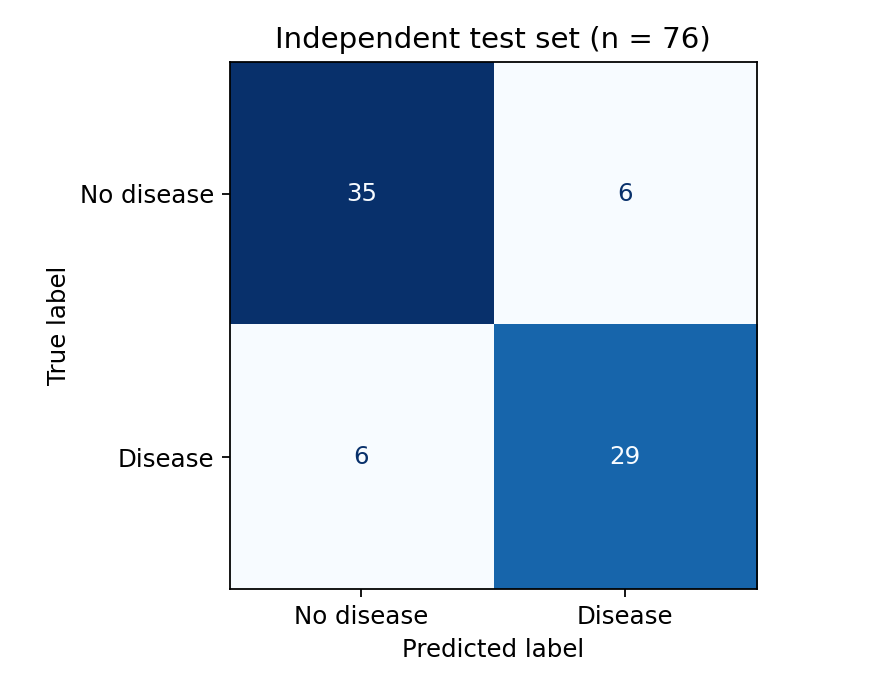

In [11]:
plt.rcParams.update({'font.size':11,'figure.dpi':160})
fig,ax=plt.subplots(figsize=(5.5,4.3));ConfusionMatrixDisplay.from_predictions(actual,pred,display_labels=['No disease','Disease'],cmap='Blues',colorbar=False,ax=ax);ax.set_title('Independent test set (n = 76)');fig.tight_layout();fig.savefig(OUT/'confusion_matrix.png');plt.close(fig)

display(Image(filename=str(OUT/"confusion_matrix.png")))

## 12 ROC and precision–recall curves
Both curves use the baseline’s test probability scores. Average precision (AP) is reported separately from trapezoidal PR area. The dashed PR reference equals test disease prevalence.

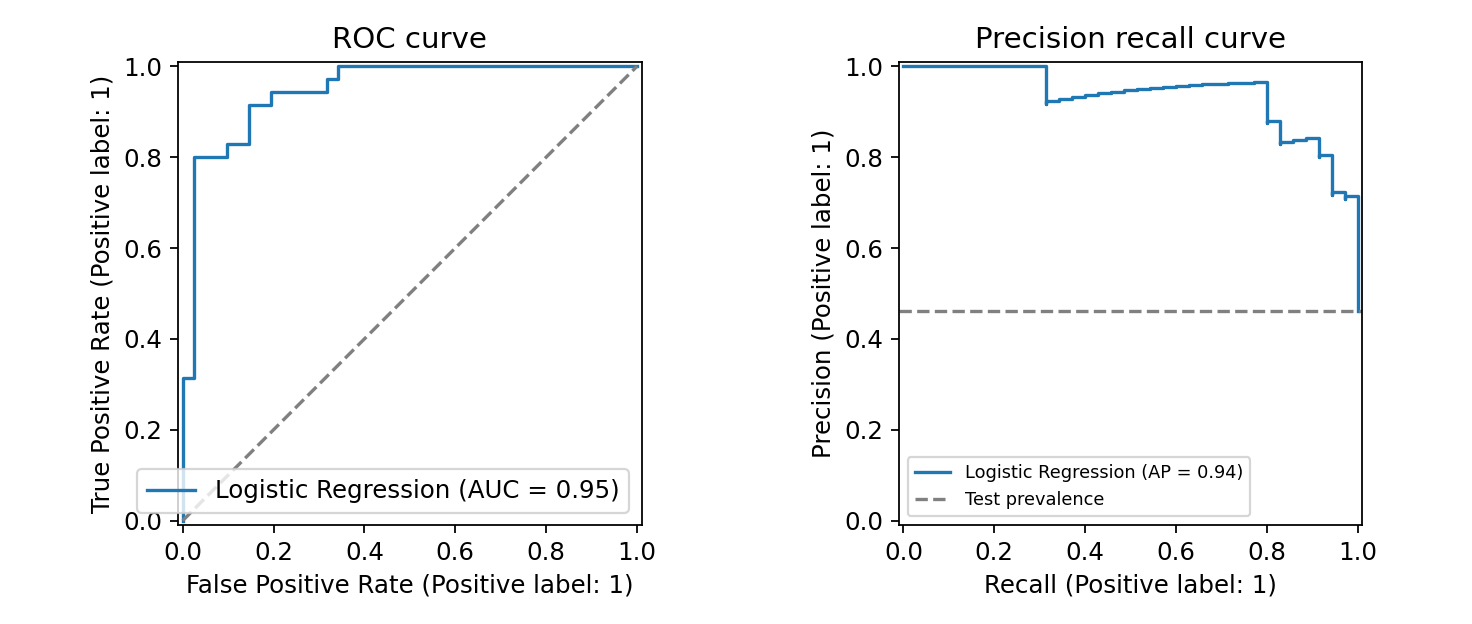

In [12]:
fig,axes=plt.subplots(1,2,figsize=(9.2,3.9))
RocCurveDisplay.from_predictions(actual,prob,ax=axes[0],name='Logistic Regression');axes[0].plot([0,1],[0,1],'--',color='gray');axes[0].set_title('ROC curve')
PrecisionRecallDisplay.from_predictions(actual,prob,ax=axes[1],name='Logistic Regression');axes[1].axhline(actual.mean(),linestyle='--',color='gray',label='Test prevalence');axes[1].set_title('Precision recall curve');axes[1].legend(fontsize=8);fig.tight_layout();fig.savefig(OUT/'roc_pr.png');plt.close(fig)

display(Image(filename=str(OUT/"roc_pr.png")))

## 13 Compare with the paper’s reported LVQ metrics
Srinivasan et al. (2023), *Scientific Reports*, DOI: **10.1038/s41598-023-40717-1**.

This is a **contextual comparison**, not a shared-cohort benchmark. Cleveland has 303 records and 13 predictors; the paper reports 503 records and ten attributes whose sample construction is unclear. The paper’s sensitivity and recall differ despite identical definitions; its F1 and accuracy also conflict with other reported metrics. Retain the values as reported and do not invent predictions to repair them. The paper’s title uses “active learning”, but its documented experiment does not establish an active label-query loop.

In [13]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy (%)", "Precision (%)", "Sensitivity (%)", "Specificity (%)", "Recall (%)", "F1 (%)", "ROC-AUC"],
    "Our Logistic Regression": [metrics["accuracy"]*100, metrics["precision"]*100, metrics["recall_sensitivity"]*100, metrics["specificity"]*100, metrics["recall_sensitivity"]*100, metrics["f1"]*100, metrics["roc_auc"]],
    "Paper reported LVQ": [98.78,98.07,97.91,97.10,95.31,97.89,0.96]
})
comparison["Reported LVQ minus baseline"] = comparison["Paper reported LVQ"] - comparison["Our Logistic Regression"]
comparison.to_csv(OUT/"paper_comparison.csv",index=False)
display(comparison.round(4))
print("ROC-AUC 0.96 is approximate as reported, not recomputed.")
print("Percentage metrics have gaps in percentage points; ROC-AUC has an absolute score gap.")

,Metric,Our Logistic Regression,Paper reported LVQ,Reported LVQ minus baseline
0,Accuracy (%),84.2105,98.78,14.5695
1,Precision (%),82.8571,98.07,15.2129
2,Sensitivity (%),82.8571,97.91,15.0529
3,Specificity (%),85.3659,97.10,11.7341
4,Recall (%),82.8571,95.31,12.4529
5,F1 (%),82.8571,97.89,15.0329
6,ROC-AUC,0.9484,0.96,0.0116


ROC-AUC 0.96 is approximate as reported, not recomputed.
Percentage metrics have gaps in percentage points; ROC-AUC has an absolute score gap.


## 14 Comparison bar chart
Five threshold-dependent metrics are displayed; sensitivity duplicates baseline recall. A zero-based scale is used. LVQ’s values are literature figures and the experiments are not directly comparable.

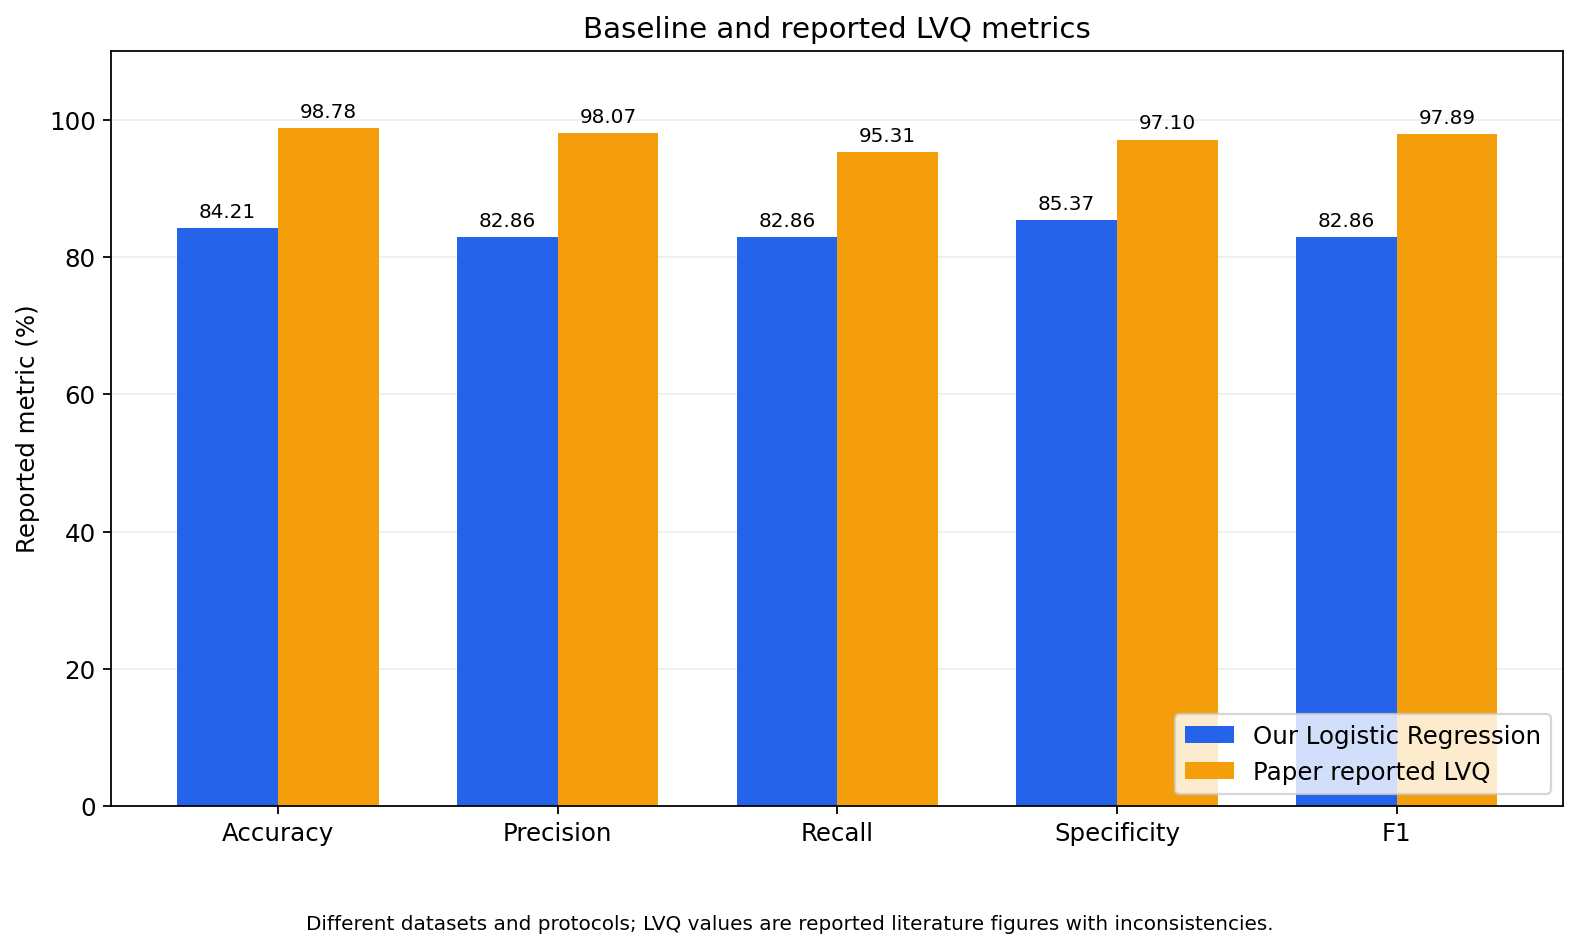

In [14]:
labels = ["Accuracy", "Precision", "Recall", "Specificity", "F1"]
baseline = [metrics["accuracy"]*100,metrics["precision"]*100,metrics["recall_sensitivity"]*100,metrics["specificity"]*100,metrics["f1"]*100]
paper_lvq = [98.78,98.07,95.31,97.10,97.89]
x = np.arange(len(labels));width=0.36
fig,ax=plt.subplots(figsize=(10,6))
a=ax.bar(x-width/2,baseline,width,label="Our Logistic Regression",color="#2563EB")
b=ax.bar(x+width/2,paper_lvq,width,label="Paper reported LVQ",color="#F59E0B")
ax.bar_label(a,fmt="%.2f",padding=3,fontsize=9);ax.bar_label(b,fmt="%.2f",padding=3,fontsize=9)
ax.set_xticks(x,labels);ax.set_ylabel("Reported metric (%)");ax.set_ylim(0,110)
ax.set_title("Baseline and reported LVQ metrics");ax.legend(loc="lower right")
ax.grid(axis="y",alpha=.2);ax.set_axisbelow(True)
fig.text(.5,.02,"Different datasets and protocols; LVQ values are reported literature figures with inconsistencies.",ha="center",fontsize=9)
fig.tight_layout(rect=[0,.08,1,1])
for name in ["baseline_vs_reported_lvq.png","model_comparison_barchart.png"]:
    fig.savefig(OUT/name,dpi=200,bbox_inches="tight")
plt.show();plt.close(fig)

## 15 Hyperparameter selection chart
Mean validation ROC-AUC against C on a logarithmic horizontal scale. Error bars show fold standard deviation, **not confidence intervals**. The highest mean determines selection; overlapping error bars do not establish a significant difference or prove underfitting/overfitting.

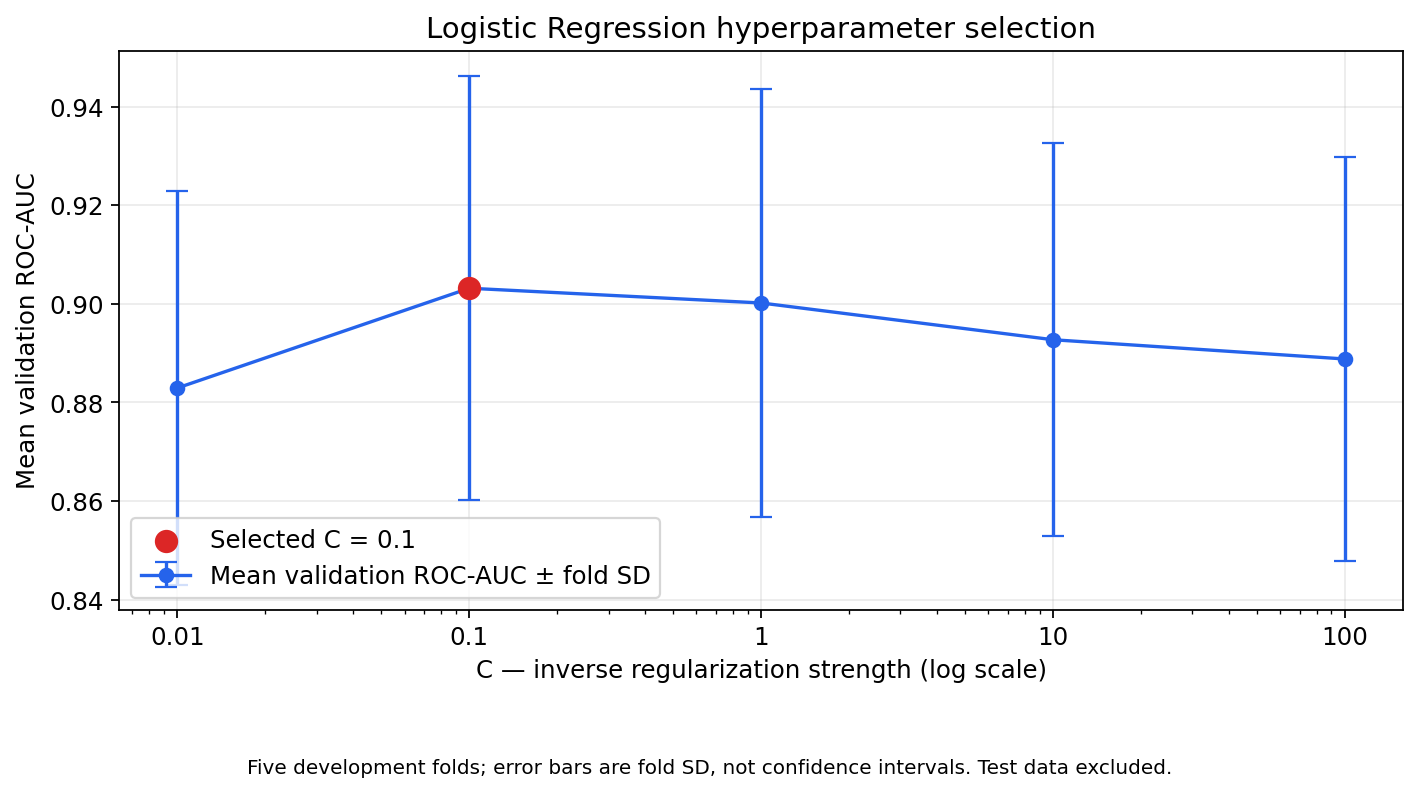

In [15]:
scores = pd.DataFrame(search.cv_results_)
scores["C"] = pd.to_numeric(scores["param_model__C"])
scores = scores.sort_values("C")
best = scores.loc[scores["mean_test_score"].idxmax()]
fig,ax=plt.subplots(figsize=(9,5))
ax.errorbar(scores["C"],scores["mean_test_score"],yerr=scores["std_test_score"],fmt="o-",capsize=5,color="#2563EB",label="Mean validation ROC-AUC ± fold SD")
ax.scatter(best["C"],best["mean_test_score"],color="#DC2626",s=90,zorder=5,label=f"Selected C = {best['C']:g}")
ax.set_xscale("log");ax.set_xticks(scores["C"]);ax.set_xticklabels([f"{c:g}" for c in scores["C"]])
ax.set_xlabel("C — inverse regularization strength (log scale)");ax.set_ylabel("Mean validation ROC-AUC")
ax.set_title("Logistic Regression hyperparameter selection");ax.grid(alpha=.25);ax.legend(loc="lower left")
fig.text(.5,.02,"Five development folds; error bars are fold SD, not confidence intervals. Test data excluded.",ha="center",fontsize=9)
fig.tight_layout(rect=[0,.1,1,1])
for name in ["c_selection_cv_auc.png","hyperparameter_tuning_curve.png"]:
    fig.savefig(OUT/name,dpi=200,bbox_inches="tight")
plt.show();plt.close(fig)

## 16 Verification and interpretation
Assertions are runtime checks, not a separate unit-test suite. The following checks confirm output structure and metric identities. The historical reference is shown as a comparison with a prior run, not a replacement for the fresh results.

In [16]:
assert len(actual)==76 and len(train_idx)==227
assert tp+tn+fp+fn==76
assert "num" not in X.columns
assert len(model.named_steps["preprocess"].get_feature_names_out())==18
assert not convergence
required = ["results.json","test_predictions.csv","split_indices.csv","cv_results.csv","coefficients.csv","confusion_matrix.png","roc_pr.png","paper_comparison.csv","baseline_vs_reported_lvq.png","c_selection_cv_auc.png"]
assert all((OUT/name).is_file() for name in required)
print("Runtime checks passed.")
print(f"Fresh accuracy: {metrics['accuracy']:.4%}; prior verified accuracy: 84.21%")
print(f"Fresh ROC-AUC: {metrics['roc_auc']:.4f}; prior verified ROC-AUC: 0.9484")
print("Six false negatives were observed in the prior run; assess current errors from the matrix.")
print("A small cohort, one test split and no external validation limit generalization.")

Runtime checks passed.
Fresh accuracy: 84.2105%; prior verified accuracy: 84.21%
Fresh ROC-AUC: 0.9484; prior verified ROC-AUC: 0.9484
Six false negatives were observed in the prior run; assess current errors from the matrix.
A small cohort, one test split and no external validation limit generalization.


## Sources
- UCI Heart Disease: https://archive.ics.uci.edu/dataset/45/heart+disease — DOI 10.24432/C52P4X.
- Selected paper: https://www.nature.com/articles/s41598-023-40717-1.
- 2024 LVQ-description correction: https://www.nature.com/articles/s41598-024-66981-3.
- scikit-learn preprocessing and leakage guidance: https://scikit-learn.org/stable/common_pitfalls.html.

No paper LVQ model is trained here. This is Option A, not a source-code review of the authors’ repository.